In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print(f"Loaded Train Dataset Shape: {train_df.shape}")
print(f"Loaded Test Dataset Shape:  {test_df.shape}")

num_features = [
    "high",
    "low",
    "momentum_index",
    "beta_indicator",
    "risk_premium",
    "volatility_factor",
    "technical_score",
    "oscillator_value",
    "liquidity_ratio",
    "open",
    "quant_index",
    "trend_strength",
    "market_sentiment",
    "volume",
    "alpha_signal",
]


Loaded Train Dataset Shape: (283085, 19)
Loaded Test Dataset Shape:  (177063, 19)


In [4]:
# Replace missing zeros in numeric indicators with NaN and impute using train medians
train_df[num_features] = train_df[num_features].replace(0, np.nan)
test_df[num_features] = test_df[num_features].replace(0, np.nan)

train_medians = train_df[num_features].median()

train_df[num_features] = train_df[num_features].fillna(train_medians)
test_df[num_features] = test_df[num_features].fillna(train_medians)

# Drop rows where target variable 'close' is invalid or zero
train_df = train_df[train_df["close"].notna() & (train_df["close"] != 0)]
test_df = test_df[test_df["close"].notna() & (test_df["close"] != 0)]

print(f"Cleaned Train Sample Count: {len(train_df)}")
print(f"Cleaned Test Sample Count:  {len(test_df)}")

Cleaned Train Sample Count: 280078
Cleaned Test Sample Count:  176495


In [5]:
unique_symbols = train_df["symbols"].unique()
dummy_cols = []

for symbol in unique_symbols:
    col_name = f"sym_{symbol}"
    train_df[col_name] = (train_df["symbols"] == symbol).astype(float)
    test_df[col_name] = (test_df["symbols"] == symbol).astype(float)
    dummy_cols.append(col_name)

all_input_features = num_features + dummy_cols

# Extract arrays
X_train_raw = train_df[all_input_features].to_numpy(dtype=np.float64)
y_train = train_df["close"].to_numpy(dtype=np.float64)

X_test_raw = test_df[all_input_features].to_numpy(dtype=np.float64)
y_test = test_df["close"].to_numpy(dtype=np.float64)

In [6]:
feature_means = np.mean(X_train_raw, axis=0)
feature_stds = np.std(X_train_raw, axis=0)

# Avoid divide-by-zero for constant columns
feature_stds[feature_stds == 0] = 1.0

X_train_scaled = (X_train_raw - feature_means) / feature_stds
X_test_scaled = (X_test_raw - feature_means) / feature_stds

# Add bias column (1s) at index 0
X_train = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
X_test = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])

In [7]:
def linear_hypothesis(X, weights):
    return X @ weights


def compute_mse_loss(X, y, weights):
    residual = linear_hypothesis(X, weights) - y
    return np.mean(residual**2)


def calculate_r2(y_true, y_pred):
    ss_residual = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (ss_residual / ss_total)


In [8]:
alpha = 0.1  # Learning rate
num_epochs = 300
num_samples, num_params = X_train.shape

weights = np.zeros(num_params)

train_loss_history = []
test_loss_history = []
train_r2_history = []
test_r2_history = []

for epoch in range(1, num_epochs + 1):
    # Gradient calculation & parameter update
    predictions = linear_hypothesis(X_train, weights)
    gradient = (2.0 / num_samples) * (X_train.T @ (predictions - y_train))
    weights -= alpha * gradient

    # Losses
    tr_loss = compute_mse_loss(X_train, y_train, weights)
    te_loss = compute_mse_loss(X_test, y_test, weights)
    train_loss_history.append(tr_loss)
    test_loss_history.append(te_loss)

    # Performance metrics (R2 Accuracy in %)
    tr_r2 = calculate_r2(y_train, linear_hypothesis(X_train, weights)) * 100.0
    te_r2 = calculate_r2(y_test, linear_hypothesis(X_test, weights)) * 100.0
    train_r2_history.append(tr_r2)
    test_r2_history.append(te_r2)

    print(
        f"Epoch {epoch:03d} | Train Cost: {tr_loss:.4f} | "
        f"Train Acc: {tr_r2:.2f}% | Test Acc: {te_r2:.2f}%"
    )

Epoch 001 | Train Cost: 3594.1070 | Train Acc: 36.33% | Test Acc: 22.31%
Epoch 002 | Train Cost: 2417.2391 | Train Acc: 57.18% | Test Acc: 42.44%
Epoch 003 | Train Cost: 1724.3095 | Train Acc: 69.46% | Test Acc: 52.61%
Epoch 004 | Train Cost: 1279.2624 | Train Acc: 77.34% | Test Acc: 59.56%
Epoch 005 | Train Cost: 988.9038 | Train Acc: 82.48% | Test Acc: 64.16%
Epoch 006 | Train Cost: 796.8047 | Train Acc: 85.89% | Test Acc: 67.31%
Epoch 007 | Train Cost: 667.6004 | Train Acc: 88.17% | Test Acc: 69.55%
Epoch 008 | Train Cost: 578.8810 | Train Acc: 89.75% | Test Acc: 71.20%
Epoch 009 | Train Cost: 516.3591 | Train Acc: 90.85% | Test Acc: 72.50%
Epoch 010 | Train Cost: 470.8914 | Train Acc: 91.66% | Test Acc: 73.56%
Epoch 011 | Train Cost: 436.6113 | Train Acc: 92.27% | Test Acc: 74.49%
Epoch 012 | Train Cost: 409.7459 | Train Acc: 92.74% | Test Acc: 75.32%
Epoch 013 | Train Cost: 387.8628 | Train Acc: 93.13% | Test Acc: 76.09%
Epoch 014 | Train Cost: 369.3894 | Train Acc: 93.46% | Test 

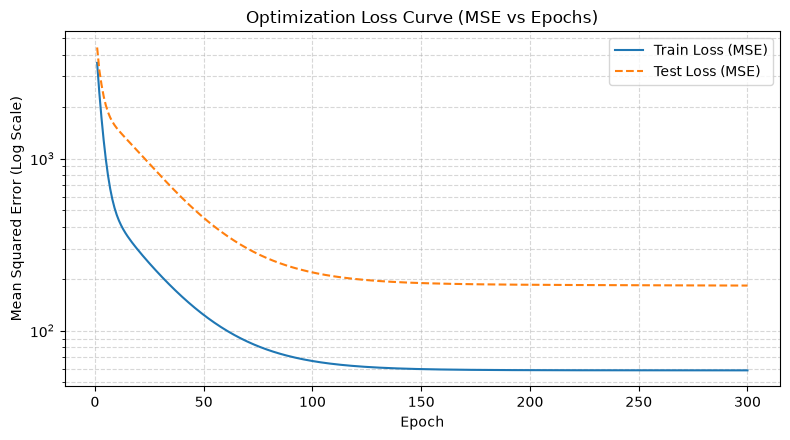

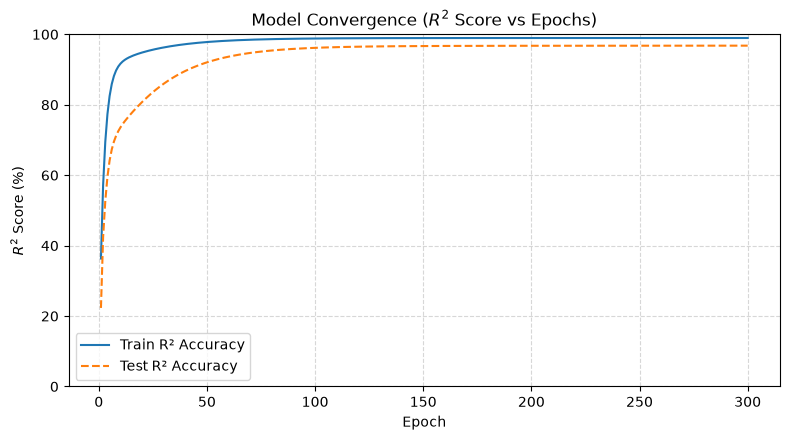


--- FIRST 20 PREDICTIONS ON TEST DATA ---
    Actual Close  Predicted Close  Abs Deviation
0          42.10            34.29           7.81
1         102.64           119.16          16.52
2          46.15            55.46           9.31
3          51.86            66.48          14.62
4          40.79            31.19           9.60
5          25.35            21.77           3.58
6          22.58            10.65          11.93
7          52.18            75.20          23.02
8          43.13            34.03           9.10
9         104.22            94.05          10.17
10        553.24           532.46          20.78
11         43.28            15.68          27.60
12         84.84           106.44          21.60
13         42.55            51.45           8.90
14         17.97            13.91           4.06
15         58.77            72.64          13.87
16         78.76            80.22           1.46
17         52.76            67.03          14.27
18         99.89          

In [9]:
# Cost Curve Plot
plt.figure(figsize=(8, 4.5))
plt.plot(
    range(1, num_epochs + 1), train_loss_history, label="Train Loss (MSE)"
)
plt.plot(
    range(1, num_epochs + 1),
    test_loss_history,
    label="Test Loss (MSE)",
    linestyle="--",
)
plt.yscale("log")
plt.title("Optimization Loss Curve (MSE vs Epochs)")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Log Scale)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

# Accuracy Curve Plot
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, num_epochs + 1), train_r2_history, label="Train R² Accuracy")
plt.plot(
    range(1, num_epochs + 1),
    test_r2_history,
    label="Test R² Accuracy",
    linestyle="--",
)
plt.title("Model Convergence ($R^2$ Score vs Epochs)")
plt.xlabel("Epoch")
plt.ylabel("$R^2$ Score (%)")
plt.ylim(0, 100)
plt.grid(True, ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=150)
plt.show()

# -------------------------------------------------------------------
# 8. Evaluation & Summary Output
# -------------------------------------------------------------------
final_test_pred = linear_hypothesis(X_test, weights)
mae_score = np.mean(np.abs(y_test - final_test_pred))
rmse_score = np.sqrt(np.mean((y_test - final_test_pred) ** 2))

summary_df = pd.DataFrame(
    {
        "Actual Close": y_test[:20],
        "Predicted Close": final_test_pred[:20],
        "Abs Deviation": np.abs(y_test[:20] - final_test_pred[:20]),
    }
)

print("\n--- FIRST 20 PREDICTIONS ON TEST DATA ---")
print(summary_df.round(2).to_string())

print("\n" + "=" * 40)
print("             MODEL PERFORMANCE           ")
print("=" * 40)
print(f"Total Epochs Run : {num_epochs}")
print(f"Learning Rate    : {alpha}")
print(f"Final Train $R^2$  : {train_r2_history[-1]:.2f}%")
print(f"Final Test $R^2$   : {test_r2_history[-1]:.2f}%")
print(f"Test MAE         : ${mae_score:.2f}")
print(f"Test RMSE        : ${rmse_score:.2f}")
print("=" * 40)